# 05 · Naive Bayes

**Naive Bayes multinomial** calcula, para cada clase, la probabilidad de las palabras de la reseña (suponiendo independencia
entre palabras) y elige la clase más probable. Es muy rápido y suele funcionar bien con texto.

- `alpha` es el **suavizado de Laplace/Lidstone**: evita probabilidades cero para palabras que no aparecieron en una clase.
- `fit_prior=False`: usa probabilidades *a priori* uniformes, para que la clase mayoritaria no gane solo por ser frecuente
  (importante porque **Envío** es minoritaria).

**Estructura del notebook** (igual para los 4 modelos, para que la comparación sea justa):
1. Cargar la partición fija (columna `particion`) y el texto preprocesado.
2. Definir el `Pipeline` TF-IDF + clasificador y la malla de hiperparámetros.
3. `GridSearchCV` con validación cruzada estratificada de 5 pliegues **solo sobre entrenamiento** (métrica: F1 macro).
4. Reentrenar con los mejores hiperparámetros y medir tiempos de entrenamiento y predicción.
5. Evaluar en prueba: accuracy, precisión, recall, F1 (macro, ponderado y por clase), matriz de confusión.
6. Guardar predicciones, métricas y el modelo (`joblib`).
7. Análisis de errores y palabras más influyentes.
8. Función para clasificar una reseña nueva.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB

import utils
from utils import CLASES, SEMILLA, RESULTADOS, MODELOS

NOMBRE = "Naive Bayes"
CLAVE = utils.MODELOS_PROYECTO[NOMBRE]          # nombre de carpeta / archivo
SALIDA = RESULTADOS / CLAVE                       # resultados/{clave}/
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

# Partición fija generada en el notebook 02 (la misma para los 4 modelos)
df, entrenamiento, prueba = utils.cargar_particiones()
X_train, y_train = entrenamiento["texto_procesado"], entrenamiento["etiqueta_reglas"]
X_test, y_test = prueba["texto_procesado"], prueba["etiqueta_reglas"]

print(f"Entrenamiento: {len(X_train)} reseñas | Prueba: {len(X_test)} reseñas")
pd.DataFrame({"entrenamiento": y_train.value_counts(), "prueba": y_test.value_counts()}).reindex(CLASES)

Entrenamiento: 11860 reseñas | Prueba: 2966 reseñas


,entrenamiento,prueba
etiqueta_reglas,,
Envío,274,68
Producto,4613,1154
Sentimiento,6973,1744


## 1. Pipeline y malla de hiperparámetros

TF-IDF + `MultinomialNB(fit_prior=False)`. Se busca el suavizado `alpha`.

In [2]:
pipeline = Pipeline([
    ("tfidf", utils.crear_vectorizador()),
    ("clf", MultinomialNB(fit_prior=False)),
])
malla = {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 0.5, 1.0]}
print("Combinaciones a evaluar:", len(malla["clf__alpha"]), "x 5 pliegues")

Combinaciones a evaluar: 6 x 5 pliegues


## 2. Búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)

`GridSearchCV` prueba todas las combinaciones con **validación cruzada estratificada de 5 pliegues** (`random_state=42`) usando
**F1 macro** como criterio (también registra accuracy). Como el TF-IDF está dentro del `Pipeline`, en cada pliegue el vocabulario
se aprende solo con los datos de entrenamiento de ese pliegue: **no hay fuga de información**. El conjunto de prueba no se toca aquí.

In [3]:
busqueda, tiempo_busqueda = utils.buscar_hiperparametros(pipeline, malla, X_train, y_train)
print(f"Tiempo total de la búsqueda: {tiempo_busqueda:.1f} s")
print("Mejores hiperparámetros:", busqueda.best_params_)

cv = utils.resumen_cv(busqueda)
print(f"F1 macro en CV (5 pliegues): {cv['cv_f1_macro_media']:.4f} ± {cv['cv_f1_macro_std']:.4f}")
print(f"Accuracy en CV (5 pliegues): {cv['cv_accuracy_media']:.4f} ± {cv['cv_accuracy_std']:.4f}")

mejores, todas = utils.tabla_busqueda(busqueda)
todas.to_csv(SALIDA / "busqueda_hiperparametros.csv", index=False, encoding="utf-8-sig")
mejores.round(4)

Tiempo total de la búsqueda: 17.7 s
Mejores hiperparámetros: {'clf__alpha': 0.1}
F1 macro en CV (5 pliegues): 0.6248 ± 0.0094
Accuracy en CV (5 pliegues): 0.7228 ± 0.0079


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,std_test_accuracy,mean_fit_time,rank_test_f1_macro
0,{'clf__alpha': 0.1},0.6248,0.0094,0.7228,0.0079,2.6857,1
1,{'clf__alpha': 0.03},0.6005,0.0112,0.7073,0.0073,2.7382,2
2,{'clf__alpha': 0.3},0.5954,0.0169,0.7336,0.0075,2.0798,3
3,{'clf__alpha': 0.01},0.5934,0.0148,0.7048,0.0090,2.4951,4
4,{'clf__alpha': 0.5},0.5550,0.0275,0.7356,0.0076,2.1822,5
5,{'clf__alpha': 1.0},0.5347,0.0232,0.7438,0.0101,2.1401,6


## 3. Reentrenar con los mejores hiperparámetros y medir tiempos

Se clona el mejor pipeline y se entrena de nuevo con **todo** el conjunto de entrenamiento, midiendo con `time.perf_counter()`:
- **Tiempo de entrenamiento:** ajuste del TF-IDF + clasificador.
- **Tiempo de predicción:** clasificar todas las reseñas de prueba.

Para que la comparación entre modelos sea justa, antes de medir se cierran los procesos auxiliares que dejó `GridSearchCV`
y la medición se repite **3 veces**, reportando la **mediana** (las predicciones son idénticas en cada repetición).

In [4]:
modelo = clone(busqueda.best_estimator_)
modelo, y_pred, t_entrenamiento, t_prediccion = utils.medir_entrenamiento_y_prediccion(modelo, X_train, y_train, X_test)
print(f"Tiempo de entrenamiento (mediana de 3): {t_entrenamiento:.3f} s")
print(f"Tiempo de predicción ({len(X_test)} reseñas): {t_prediccion:.3f} s "
      f"({1000 * t_prediccion / len(X_test):.3f} ms por reseña)")

Tiempo de entrenamiento (mediana de 3): 2.113 s
Tiempo de predicción (2966 reseñas): 0.195 s (0.066 ms por reseña)


## 4. Evaluación en el conjunto de prueba

In [5]:
metricas = utils.calcular_metricas(y_test, y_pred)
metricas.update(cv)
metricas.update({
    "tiempo_busqueda_s": tiempo_busqueda,
    "tiempo_entrenamiento_s": t_entrenamiento,
    "tiempo_prediccion_s": t_prediccion,
    "mejores_hiperparametros": {k: str(v) for k, v in busqueda.best_params_.items()},
})
metricas = utils.guardar_metricas(NOMBRE, metricas, SALIDA)
reporte = utils.guardar_reporte(NOMBRE, y_test, y_pred, metricas, SALIDA)
print(reporte)
print(f"Accuracy: {metricas['accuracy']:.4f} | F1 macro: {metricas['f1_macro']:.4f} | "
      f"F1 ponderado: {metricas['f1_ponderado']:.4f} | Errores: {metricas['n_errores']} de {metricas['n_prueba']}")

              precision    recall  f1-score   support

       Envío     0.3117    0.3529    0.3310        68
    Producto     0.6219    0.8068    0.7024      1154
 Sentimiento     0.8484    0.6772    0.7532      1744

    accuracy                         0.7202      2966
   macro avg     0.5940    0.6123    0.5955      2966
weighted avg     0.7480    0.7202    0.7237      2966

Accuracy: 0.7202 | F1 macro: 0.5955 | F1 ponderado: 0.7237 | Errores: 830 de 2966


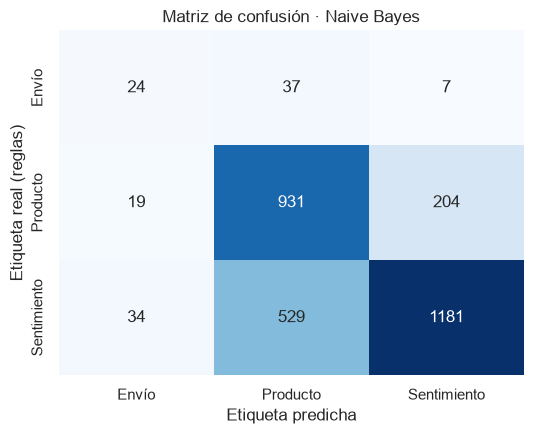

,pred_Envío,pred_Producto,pred_Sentimiento
real_Envío,24,37,7
real_Producto,19,931,204
real_Sentimiento,34,529,1181


In [6]:
matriz = utils.graficar_matriz_confusion(y_test, y_pred, f"Matriz de confusión · {NOMBRE}", SALIDA)
plt.show()
matriz

## 5. Guardar predicciones y modelo

- `predicciones_prueba.csv`: texto, estrellas, etiqueta real (reglas), etiqueta predicha, si acertó y la confianza por clase.
- `modelos/<modelo>.joblib`: el pipeline completo (TF-IDF + clasificador), listo para clasificar texto preprocesado.
- `mejores_hiperparametros.json`.

In [7]:
predicciones = utils.guardar_predicciones(prueba, y_pred, modelo, SALIDA)
joblib.dump(modelo, MODELOS / f"{CLAVE}.joblib")
with open(SALIDA / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(metricas["mejores_hiperparametros"], f, ensure_ascii=False, indent=2)
print("Guardados:", (SALIDA / "predicciones_prueba.csv").relative_to(utils.BASE), "|",
      (MODELOS / f"{CLAVE}.joblib").relative_to(utils.BASE))
predicciones.head()

Guardados: resultados\naive_bayes\predicciones_prueba.csv | modelos\naive_bayes.joblib


,id,text,rating,polarity,etiqueta_real,etiqueta_predicha,correcta,confianza_Envío,confianza_Producto,confianza_Sentimiento
0,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B004OF968O_1493389988000,"Not for me..... I was not expecting much, but for me, these bags are a joke. I can't believe so many are still available, but impossible to find out who actually makes them. I wanted to make a s...",1.0,negative,Sentimiento,Producto,False,0.0064,0.7764,0.2172
1,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B00P9UC004_1521055721867,"Very small size. These are so small everything falls off. Too small for baseball caps, they just fall off. The pictures do not show the scale. Good if you want to hang a few rubber bands on hoo...",1.0,negative,Producto,Sentimiento,False,0.0720,0.4388,0.4892
2,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B081B65WT8_1591466996903,Did not work for me. I always have a problem when cooking pasta sauce on my glass stove top. I purchased a counter top induction burner and a new SS 16 qt stock pot along with this item. $$$$$ s...,2.0,negative,Producto,Producto,True,0.0235,0.7276,0.2489
3,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08G7Y67GH_1617298313281,UPDATE. Originally said this was a good deal....does the job.....bit after only three times with an egg one of the wires broke and hangs loose so now the slicer is useless. NOT a good deal and no...,1.0,negative,Producto,Producto,True,0.1138,0.8336,0.0526
4,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08NVKYLGV_1521054740535,"Should have sent it back...!!. I like the product just fine, but almost returned it because the large product label was so hard to remove, I ended up scratching the plastic. Now every time the lig...",2.0,negative,Producto,Producto,True,0.1499,0.6654,0.1847


## 6. Análisis de errores

### 6.1 ¿Qué confusiones son más frecuentes? Ejemplos reales

In [8]:
conteo_errores, ejemplos = utils.ejemplos_errores(predicciones, SALIDA, n_por_tipo=3)
display(conteo_errores)
for (real, pred), grupo in ejemplos.groupby(["etiqueta_real", "etiqueta_predicha"], sort=False):
    print(f"\n--- Real: {real}  ->  Predicha: {pred} ---")
    for _, fila in grupo.iterrows():
        print(f"  [{int(fila['rating'])}★] {fila['text']}")

,etiqueta_real,etiqueta_predicha,n_errores
0,Sentimiento,Producto,529
1,Producto,Sentimiento,204
2,Envío,Producto,37
3,Sentimiento,Envío,34
4,Producto,Envío,19
5,Envío,Sentimiento,7



--- Real: Sentimiento  ->  Predicha: Producto ---
  [3★] It's Ok. I have cats and I needed a vacuum that would pick up cat hair, this vacuum is Good for the money but is very limited in use,
  [3★] ships wheel bath mat. I purchased this along with a couple of the same type with different prints.  A real disappointment.  They come folded and the creases don't come out even with washing and drying.  Eh.  The backing does have some dots that help make it less slippery.  To be honest, I'm going ba
  [1★] Wanted to love it. This could be so awesome but there is a place right in the head where the glaze completely missed so it looks awful.

--- Real: Producto  ->  Predicha: Sentimiento ---
  [4★] EASY shelf protection (not sticky/ glue-y). Not sticky exactly, but Defo no bubbles/wrinkles/ kinks EASY TO USE Used it to line and protect my window sills fresh paint job from moist potted plants:) working real good so far, the long skinny one was perfect, didn't even need to cut it
  [3★] Yellowe

### 6.2 ¿Se clasifican peor las reseñas de 3 estrellas (neutral)?

In [9]:
por_polaridad = utils.desempeno_por_polaridad(predicciones, SALIDA)
por_polaridad.round(4)

,polaridad,n,accuracy,f1_macro
0,negative,955,0.6712,0.5621
1,neutral,1022,0.6507,0.5067
2,positive,989,0.8392,0.5082


### 6.3 Palabras más influyentes por clase

Para cada clase se ordena el vocabulario por **log P(palabra | clase) − promedio de log P(palabra | otras clases)**:
cuanto mayor, más "empuja" esa palabra hacia la clase.

In [10]:
nb_clf, tfidf = modelo.named_steps["clf"], modelo.named_steps["tfidf"]
vocabulario = tfidf.get_feature_names_out()
logp = nb_clf.feature_log_prob_
pesos = np.array([logp[i] - np.delete(logp, i, axis=0).mean(axis=0) for i in range(len(nb_clf.classes_))])
influyentes = utils.palabras_influyentes_lineales(pesos, vocabulario, nb_clf.classes_, n=15)
influyentes.to_csv(SALIDA / "palabras_influyentes.csv", index=False, encoding="utf-8-sig")
influyentes

,Envío,Producto,Sentimiento
0,arrive broken (6.09),not stay (4.41),five star (3.10)
1,come broken (5.59),not work (3.52),daughter love (2.79)
2,come damage (5.22),not fit (3.17),star great (2.77)
3,arrive bent (5.18),stink (3.00),love pillow (2.74)
4,arrive late (4.87),doesnt fit (2.99),love great (2.56)
5,arrive break (4.61),not stick (2.96),great quality (2.55)
6,inside package (4.55),useless (2.92),arrive fast (2.47)
7,come bent (4.55),stop work (2.89),gift love (2.39)
8,never receive (4.52),poor design (2.87),love love (2.38)
9,poor packaging (4.49),hold much (2.76),great value (2.37)


## 7. Clasificar una reseña nueva

La reseña se preprocesa exactamente igual que en el entrenamiento (`utils.preprocesar_texto`) y luego pasa por el pipeline
(TF-IDF + clasificador).

In [11]:
def clasificar_texto(texto):
    procesado = utils.preprocesar_texto(texto)
    confianzas, tipo = utils.puntajes_confianza(modelo, [procesado])
    etiqueta = modelo.predict([procesado])[0]
    detalle = {c: round(float(p), 3) for c, p in zip(modelo.classes_, confianzas[0])}
    return etiqueta, detalle

for resena in ["The box arrived crushed and two glasses were broken.",
               "The blender stopped working after a week, the motor smells like burning.",
               "Absolutely love these towels, they are soft and beautiful!"]:
    etiqueta, detalle = clasificar_texto(resena)
    print(f"{etiqueta:12s} {detalle}  <-  {resena}")

Envío        {np.str_('Envío'): 0.889, np.str_('Producto'): 0.096, np.str_('Sentimiento'): 0.014}  <-  The box arrived crushed and two glasses were broken.
Producto     {np.str_('Envío'): 0.011, np.str_('Producto'): 0.977, np.str_('Sentimiento'): 0.012}  <-  The blender stopped working after a week, the motor smells like burning.
Sentimiento  {np.str_('Envío'): 0.037, np.str_('Producto'): 0.07, np.str_('Sentimiento'): 0.893}  <-  Absolutely love these towels, they are soft and beautiful!
